<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Workload is not a completion time

**If the busiest machine has ten minutes of work, can the whole batch finish in ten minutes?**
Three jobs share three machines. SQL will assemble the operations, measure simple lower
bounds, ask CP-SAT for a schedule, and check whether the returned rows obey the model.
Then we will lengthen one operation and see how much of that delay reaches completion.

The inputs are **synthetic**, adapted from this repository's small job-shop test fixture.
Job and machine names are illustrative. Every job is released at minute zero; each
operation is non-preemptive, machines process one operation at a time, and each job
follows its task order. There are no setup times, breakdowns, shifts, transfer delays,
or due-date penalties. The objective is the final finishing time, called **makespan**.

## Choose one operation's duration

`A_CUT_MINUTES` is Job A's first operation on the Cutter. Accept integer minutes **1–10**;
default **3**, experiment **6**. Edit this cell, then **Restart Kernel → Run All**.

One solver tick equals one minute. All input durations are exact integers; no rounding
is performed. For subminute data, choose a common integer scale first (for example,
seconds = minutes × 60), and scale durations, horizons, output labels and comparisons
together. Time below is elapsed from batch release, with intervals `[start, end)`.

In [1]:
A_CUT_MINUTES = 3

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from notebook_support import COLORS, finish, prose, theme

if isinstance(A_CUT_MINUTES, bool) or not isinstance(A_CUT_MINUTES, int) or not 1 <= A_CUT_MINUTES <= 10:
    raise ValueError("A_CUT_MINUTES must be an integer from 1 to 10.")
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ortools/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ortools/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ortools/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-ortools/notebooks/pyproject.toml.

## Connect to the pinned solver

The literal `uvx` command below runs the published **v0.4.0** Git revision with a
compatible pinned SDK. Git and uv/uvx must be on PATH; no worker checkout or root
installation is needed. The notebook environment pins published Haybarn **2.0.0rc11**.
First use downloads and caches the worker; solving runs locally without external
requests. See [runtime prerequisites and upgrading](README.md).

`solve_jobshop` uses the worker's **single-threaded CP-SAT** default, a fixed seed of
1, and a five-second search cap. The table below records actual worker versions.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ortools' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-ortools@4f2e5c6715c50ca86038a1e868dc9437b7e30c3a vgi-ortools');
SELECT component, version FROM ortools.main.solver_info ORDER BY component;

,component,version
0,cp_sat,9.15.6755
1,dialect,1
2,glop,9.15.6755
3,ortools,9.15.6755
4,pdlp,9.15.6755
5,worker,0.4.0


## From operation rows to a solver matrix

The fixture has eight operations. `task` is the precedence index within a job, not a
priority between jobs. Machine labels help us interpret the output; the worker consumes
integer IDs. Only A's first operation takes its duration from the parameter.

In [5]:
%%sql
CREATE OR REPLACE TABLE machines AS
SELECT * FROM (VALUES (0, 'Cutter'), (1, 'Mill'), (2, 'Finisher')) AS m(machine, machine_name);
CREATE OR REPLACE TABLE fixture AS
SELECT * FROM (VALUES
    (0, 'A', 0, 0, 3), (0, 'A', 1, 1, 2), (0, 'A', 2, 2, 2),
    (1, 'B', 0, 0, 2), (1, 'B', 1, 2, 1), (1, 'B', 2, 1, 4),
    (2, 'C', 0, 1, 4), (2, 'C', 1, 2, 3)
) AS f(job, job_name, task, machine, base_minutes);
CREATE OR REPLACE TABLE operations AS
SELECT job, job_name, task, machine,
       CASE WHEN job = 0 AND task = 0 THEN {{ A_CUT_MINUTES }}
            ELSE base_minutes END::BIGINT AS duration_min
FROM fixture;
SELECT job_name, task, machine_name, duration_min
FROM operations JOIN machines USING (machine) ORDER BY job, task;

,job_name,task,machine_name,duration_min
0,A,0,Cutter,3
1,A,1,Mill,2
2,A,2,Finisher,2
3,B,0,Cutter,2
4,B,1,Finisher,1
5,B,2,Mill,4
6,C,0,Mill,4
7,C,1,Finisher,3


## Two lower bounds before we optimize

A machine cannot finish its own workload sooner than the sum of its operation durations.
Likewise, a job cannot finish sooner than the sum of its sequential operations. The
maximum of those sums is a **lower bound**, not necessarily an attainable schedule:
it ignores how jobs compete for machines at particular times.

In [6]:
%%sql bounds <<
CREATE OR REPLACE TABLE lower_bounds AS
SELECT 'Machine workload' AS bound_type, machine_name AS entity,
       sum(duration_min)::BIGINT AS bound_min
FROM operations JOIN machines USING (machine) GROUP BY machine_name
UNION ALL
SELECT 'Job chain' AS bound_type, 'Job ' || job_name AS entity,
       sum(duration_min)::BIGINT AS bound_min
FROM operations GROUP BY job_name;
SELECT * FROM lower_bounds ORDER BY bound_type DESC, bound_min DESC, entity;

In [7]:
display(bounds)
lower_bound = int(bounds.bound_min.max())
leaders = ", ".join(bounds.loc[bounds.bound_min == lower_bound, "entity"])
prose(
    f"The strongest simple bound is **{lower_bound} minutes**, set by **{leaders}**. "
    "A schedule below that value is impossible. We still need to establish whether "
    "all jobs can share the machines without extending the batch beyond it."
)

,bound_type,entity,bound_min
0,Machine workload,Mill,10
1,Machine workload,Finisher,6
2,Machine workload,Cutter,5
3,Job chain,Job A,7
4,Job chain,Job B,7
5,Job chain,Job C,7


The strongest simple bound is **10 minutes**, set by **Mill**. A schedule below that value is impossible. We still need to establish whether all jobs can share the machines without extending the batch beyond it.

## Solve once, then analyze returned rows

`array_agg` creates the scalar `BIGINT[][]` matrix `[job, task, machine, duration]`.
The matrix cell below serializes that integer list as JSON (also valid SQL list syntax).
A small folded Python cell transfers the scalar text to JupySQL interpolation. This
keeps the worker argument constant: table functions reject scalar subqueries, and
JupySQL opens separate cursors whose `SET VARIABLE` values would not be shared.
`horizon := 0` asks the worker to use the sum of durations, a safe upper bound here:
processing every operation serially in job order is feasible.

For this **CP-SAT** model, `OPTIMAL` means the makespan has been proved minimal.
`FEASIBLE` means a schedule was found but minimality was not proved before the time
limit. `UNKNOWN` means no solution was established; `INFEASIBLE` means the constraints
cannot all be satisfied. A no-solution result is one status row with NULL task data,
never zero rows. Malformed inputs may instead raise a validation error.

In [8]:
%%sql matrices <<
SELECT (SELECT to_json(array_agg([job, task, machine, duration_min]::BIGINT[] ORDER BY job, task))
        FROM operations) AS selected_tasks,
       (SELECT to_json(array_agg([job, task, machine, base_minutes]::BIGINT[] ORDER BY job, task))
        FROM fixture) AS reference_tasks;

In [9]:
task_matrix_sql = str(matrices.selected_tasks.iloc[0])
reference_matrix_sql = str(matrices.reference_tasks.iloc[0])

In [10]:
%%sql schedule <<
CREATE OR REPLACE TABLE solve_rows AS
SELECT * FROM ortools.main.solve_jobshop(
    tasks := {{ task_matrix_sql }}::BIGINT[][], horizon := 0,
    time_limit_s := 5.0, random_seed := 1
);
CREATE OR REPLACE TABLE schedule AS
SELECT s.*, o.job_name, m.machine_name, o.duration_min
FROM solve_rows s JOIN operations o USING (job, task, machine)
JOIN machines m USING (machine)
WHERE s.status IN ('OPTIMAL', 'FEASIBLE');
SELECT * FROM schedule ORDER BY machine, start, job;

In [11]:
%%sql solution_summary <<
WITH summary AS (
    SELECT min(status) AS status, count(*) AS returned_rows,
           count(job) AS scheduled_operations, max(makespan) AS makespan_min,
           (SELECT max(bound_min) FROM lower_bounds) AS simple_bound_min
    FROM solve_rows
)
SELECT *, makespan_min - simple_bound_min AS gap_to_simple_bound_min FROM summary;

In [12]:
display(solution_summary)
status = solution_summary.status.iloc[0]
if status not in {"OPTIMAL", "FEASIBLE"}:
    raise RuntimeError(f"Unconstrained solve returned {status}; no schedule chart can be drawn.")
makespan = int(solution_summary.makespan_min.iloc[0])
gap = int(solution_summary.gap_to_simple_bound_min.iloc[0])
qualification = "proven minimum" if status == "OPTIMAL" else "best found within the search cap"
prose(
    f"The solver returned **{status}** with a makespan of **{makespan} minutes** ({qualification}). "
    f"That is **{gap} {'minute' if gap == 1 else 'minutes'} above** the {lower_bound}-minute workload/chain bound. "
    "The difference measures how loose our simple bound is; it is not a solver optimality gap."
)

,status,returned_rows,scheduled_operations,makespan_min,simple_bound_min,gap_to_simple_bound_min
0,OPTIMAL,8,8,11,10,1


The solver returned **OPTIMAL** with a makespan of **11 minutes** (proven minimum). That is **1 minute above** the 10-minute workload/chain bound. The difference measures how loose our simple bound is; it is not a solver optimality gap.

## The capacity view: workload versus finish time

Compare each machine's processing total with the same batch makespan. Empty time on
a machine is expected when it is waiting for a predecessor or has finished all its work.
Those gaps do not by themselves show that the schedule can be shortened.

In [13]:
%%sql machine_load <<
SELECT machine, machine_name, job_name, sum(duration_min)::BIGINT AS busy_min
FROM operations JOIN machines USING (machine)
GROUP BY machine, machine_name, job_name ORDER BY machine, job_name;

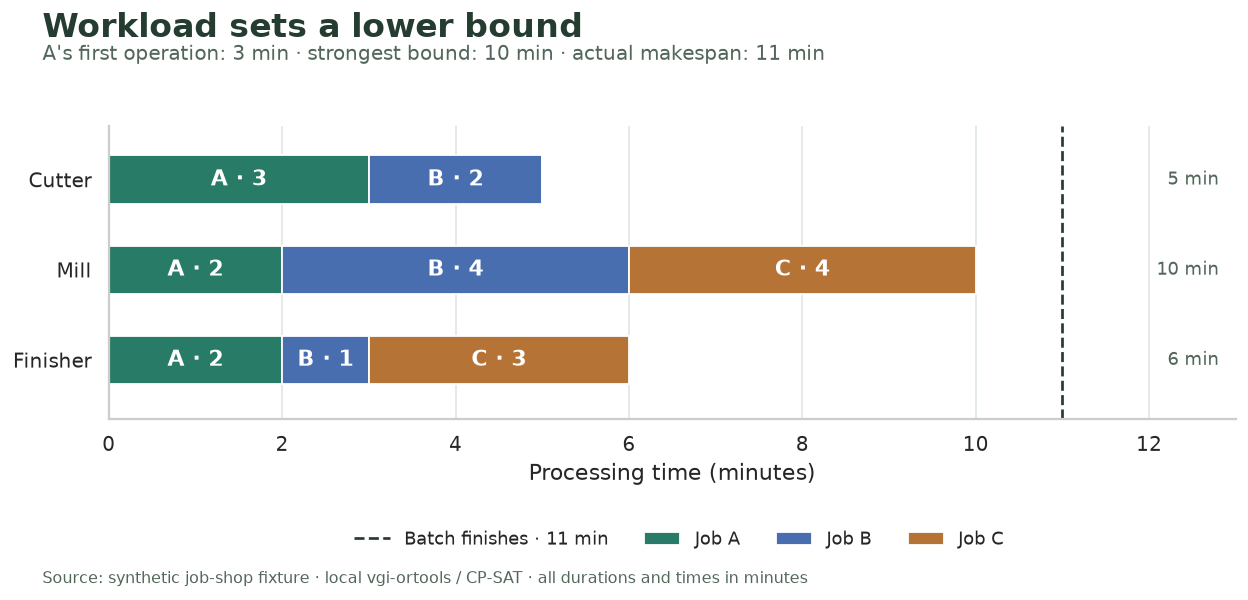

In [14]:
fig, ax = plt.subplots(figsize=(10.2, 4.6))
labels = machine_load[["machine", "machine_name"]].drop_duplicates().sort_values("machine")
positions = np.arange(len(labels))
left = np.zeros(len(labels))
for job, color in COLORS.items():
    values = (
        machine_load[machine_load.job_name == job]
        .set_index("machine")
        .busy_min.reindex(labels.machine, fill_value=0)
        .to_numpy()
    )
    ax.barh(positions, values, left=left, color=color, height=0.54, label=f"Job {job}")
    for y, start, width in zip(positions, left, values, strict=True):
        if width:
            ax.text(start + width / 2, y, f"{job} · {width:g}", ha="center", va="center", color="white", weight="bold")
    left += values
for y, total in zip(positions, left, strict=True):
    ax.text(makespan + 1.8, y, f"{total:g} min", ha="right", va="center", color="#52675a", fontsize=10)
ax.axvline(makespan, color="#283b32", linestyle="--", linewidth=1.5, label=f"Batch finishes · {makespan} min")
ax.set(
    yticks=positions,
    yticklabels=labels.machine_name,
    xlabel="Processing time (minutes)",
    xlim=(0, makespan + 2),
    ylim=(-0.6, 2.65),
)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.55, 0.14), bbox_transform=fig.transFigure, ncol=4, frameon=False, fontsize=10
)
finish(
    fig,
    "Workload sets a lower bound",
    f"A's first operation: {A_CUT_MINUTES} min · strongest bound: {lower_bound} min · actual makespan: {makespan} min",
    f"workloads-a{A_CUT_MINUTES}.png",
)

## The sequence view: where the minutes go

Each block below is an actual returned `[start, end)` interval. Color identifies the job;
its task number makes precedence readable across machine rows. White gaps are unused
machine time, not missing data. Several equally good schedules may exist.

The table beneath the chart separates processing minutes from each machine's last
finish time. Their difference counts idle minutes before that last finish.

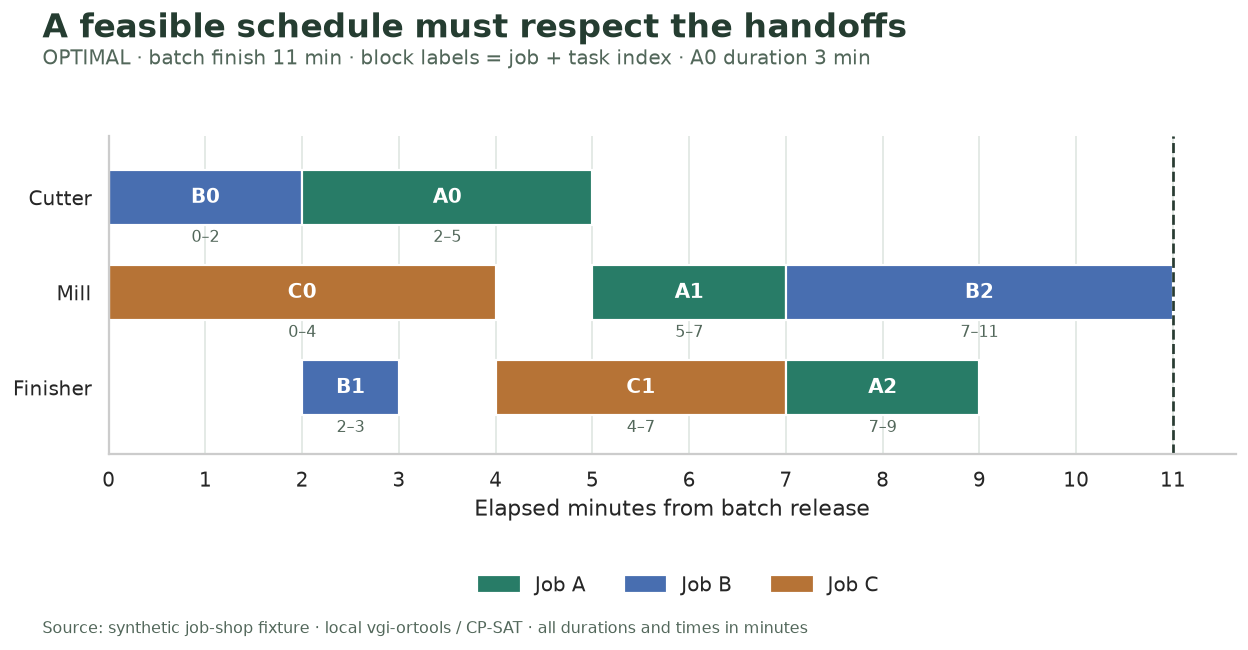

In [15]:
fig, ax = plt.subplots(figsize=(10.2, 5.0))
for row in schedule.itertuples():
    ax.barh(
        row.machine,
        row.duration_min,
        left=row.start,
        height=0.58,
        color=COLORS[row.job_name],
        edgecolor="white",
        linewidth=1.2,
    )
    ax.text(
        row.start + row.duration_min / 2,
        row.machine,
        f"{row.job_name}{row.task}",
        ha="center",
        va="center",
        color="white",
        weight="bold",
        fontsize=11,
    )
    ax.text(
        row.start + row.duration_min / 2,
        row.machine + 0.42,
        f"{row.start}–{row.end}",
        ha="center",
        va="center",
        color="#52675a",
        fontsize=9,
    )
ax.axvline(makespan, color="#283b32", linestyle="--", linewidth=1.5)
ax.set(
    yticks=[0, 1, 2],
    yticklabels=["Cutter", "Mill", "Finisher"],
    xlabel="Elapsed minutes from batch release",
    xlim=(0, makespan + 0.65),
    ylim=(-0.65, 2.7),
)
ax.invert_yaxis()
ax.set_xticks(range(makespan + 1))
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.legend(
    handles=[Patch(color=color, label=f"Job {job}") for job, color in COLORS.items()],
    loc="upper center",
    bbox_to_anchor=(0.55, 0.14),
    bbox_transform=fig.transFigure,
    ncol=3,
    frameon=False,
)
finish(
    fig,
    "A feasible schedule must respect the handoffs",
    f"{status} · batch finish {makespan} min · block labels = job + task index · A0 duration {A_CUT_MINUTES} min",
    f"schedule-a{A_CUT_MINUTES}.png",
)

In [16]:
%%sql machine_timing <<
SELECT machine, machine_name, sum(duration_min)::BIGINT AS processing_min,
       max("end") AS last_finish_min,
       max("end") - sum(duration_min)::BIGINT AS idle_before_last_finish_min
FROM schedule GROUP BY machine, machine_name ORDER BY machine;

In [17]:
display(machine_timing)
busiest = machine_timing.sort_values(["processing_min", "machine"], ascending=[False, True]).iloc[0]
final_tasks = schedule.loc[schedule["end"] == makespan]
finishers = ", ".join(f"{r.machine_name} ({r.job_name}{r.task})" for r in final_tasks.itertuples())
prose(
    f"The **{busiest.machine_name}** processes **{int(busiest.processing_min)} minutes** of work "
    f"and finishes its last operation at minute **{int(busiest.last_finish_min)}**, with "
    f"**{int(busiest.idle_before_last_finish_min)} idle "
    f"{'minute' if busiest.idle_before_last_finish_min == 1 else 'minutes'}** before that finish. "
    f"The batch's final operation(s) are on **{finishers}**. "
    "These timings describe the returned schedule; CP-SAT's status tells us whether a shorter schedule is possible."
)

,machine,machine_name,processing_min,last_finish_min,idle_before_last_finish_min
0,0,Cutter,5,5,0
1,1,Mill,10,11,1
2,2,Finisher,6,9,3


The **Mill** processes **10 minutes** of work and finishes its last operation at minute **11**, with **1 idle minute** before that finish. The batch's final operation(s) are on **Mill (B2)**. These timings describe the returned schedule; CP-SAT's status tells us whether a shorter schedule is possible.

## Check the model, not just the picture

SQL compares each operation with its predecessor, checks every pair sharing a machine,
and reconciles durations and makespan. The checks also require exactly one returned
row per input operation. A zero violation count alone would be insufficient if all
operations were missing.

In [18]:
%%sql checks <<
WITH ordered AS (
    SELECT *, lag("end") OVER (PARTITION BY job ORDER BY task) AS predecessor_end
    FROM schedule
), checks AS (
    SELECT 'Missing or duplicate operations' AS check_name,
       (SELECT count(*) FROM (
           SELECT o.job, o.task FROM operations o LEFT JOIN schedule s USING (job, task)
           GROUP BY o.job, o.task HAVING count(s.job) <> 1)) AS violations
    UNION ALL
    SELECT 'Job precedence', count(*) FROM ordered WHERE start < predecessor_end
    UNION ALL
    SELECT 'Machine overlap', count(*) FROM schedule a JOIN schedule b
      ON a.machine = b.machine AND (a.job, a.task) < (b.job, b.task)
     AND a.start < b."end" AND b.start < a."end"
    UNION ALL
    SELECT 'Duration or time bounds', count(*) FROM schedule
      WHERE "end" - start <> duration_min OR start < 0 OR "end" > makespan
    UNION ALL
    SELECT 'Makespan agreement', CASE WHEN max("end") = min(makespan)
      AND min(makespan) = max(makespan) THEN 0 ELSE 1 END FROM schedule
    UNION ALL
    SELECT 'Lower bound', count(*) FROM solve_rows
      WHERE makespan < (SELECT max(bound_min) FROM lower_bounds)
)
SELECT * FROM checks ORDER BY check_name;

In [19]:
display(checks)
assert (checks.violations == 0).all(), "The returned schedule violates a modeled invariant."
assert len(schedule) == int(solution_summary.scheduled_operations.iloc[0])
prose(
    f"All **{len(checks)} invariant checks pass** for **{len(schedule)} operations**. "
    "These checks establish consistency with the stated model. They cannot establish "
    "that omitted setup times or breakdowns are unimportant in a real workshop."
)

,check_name,violations
0,Duration or time bounds,0
1,Job precedence,0
2,Lower bound,0
3,Machine overlap,0
4,Makespan agreement,0
5,Missing or duplicate operations,0


All **6 invariant checks pass** for **8 operations**. These checks establish consistency with the stated model. They cannot establish that omitted setup times or breakdowns are unimportant in a real workshop.

## Can we finish one minute sooner?

Use the current makespan minus one minute as a hard scheduling horizon. If the earlier
status was `OPTIMAL`, this tighter model is mathematically infeasible, although another capped search can
still return `UNKNOWN` if it runs out of time. If it was only `FEASIBLE`,
this follow-up could find an improvement or remain unresolved. Inspect the raw status
row before joining task IDs: an inner join would erase a no-solution row.

In [20]:
%%sql deadline_result <<
SELECT {{ makespan }} - 1 AS horizon_min, *
FROM ortools.main.solve_jobshop(tasks := {{ task_matrix_sql }}::BIGINT[][],
    horizon := {{ makespan }} - 1, time_limit_s := 5.0, random_seed := 1);

In [21]:
display(deadline_result)
deadline_status = deadline_result.status.iloc[0]
horizon = int(deadline_result.horizon_min.iloc[0])
if status == "OPTIMAL":
    assert deadline_status not in {"OPTIMAL", "FEASIBLE"}, (
        "A tighter feasible schedule contradicts the earlier optimality proof."
    )
if deadline_status in {"INFEASIBLE", "UNKNOWN", "MODEL_INVALID"}:
    assert len(deadline_result) == 1
    assert deadline_result[["job", "task", "machine", "start", "end", "makespan"]].isna().all().all()
if deadline_status == "INFEASIBLE":
    prose(
        f"The **{horizon}-minute** horizon returns **INFEASIBLE**, with exactly one row and NULL task data. "
        "This is a proven scheduling contradiction under the model, not an empty successful schedule."
    )
else:
    prose(
        f"The **{horizon}-minute** horizon returns **{deadline_status}**. "
        "Only INFEASIBLE would prove that this deadline cannot be met; inspect any returned schedule separately."
    )

,horizon_min,job,task,machine,start,end,makespan,status
0,10,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,INFEASIBLE


The **10-minute** horizon returns **INFEASIBLE**, with exactly one row and NULL task data. This is a proven scheduling contradiction under the model, not an empty successful schedule.

## Experiment: add three minutes to A's first operation

Change **`A_CUT_MINUTES = 3` to `6`**, then restart and run all. Before doing so, predict
whether the batch will grow by all three minutes. The busiest machine's total may
stay unchanged while the order of work changes on another machine.

The SQL below solves the original input again through VGI and places its result beside
the selected run. Compare the makespan delta, lower-bound delta, and A/B ordering on
the Gantt chart. The selected operation is the **only changed input**. Reset to **3**.
This is a deterministic toy sensitivity check, not a claim that a larger workshop
has the same response or that one schedule is uniquely optimal.

In [22]:
%%sql comparison <<
CREATE OR REPLACE TABLE reference_rows AS
SELECT * FROM ortools.main.solve_jobshop(tasks := {{ reference_matrix_sql }}::BIGINT[][],
    horizon := 0, time_limit_s := 5.0, random_seed := 1);
WITH reference_bounds AS (
    SELECT sum(base_minutes) AS bound_min FROM fixture GROUP BY machine
    UNION ALL
    SELECT sum(base_minutes) FROM fixture GROUP BY job
), results AS (
    SELECT 'Reference' AS scenario, 3 AS a_cut_min,
           min(status) AS status, max(makespan) AS makespan_min,
           (SELECT max(bound_min) FROM reference_bounds) AS simple_bound_min
    FROM reference_rows
    UNION ALL
    SELECT 'Selected', {{ A_CUT_MINUTES }}, min(status), max(makespan),
           (SELECT max(bound_min) FROM lower_bounds)
    FROM solve_rows
)
SELECT *, makespan_min - simple_bound_min AS gap_to_simple_bound_min,
       makespan_min - (SELECT max(makespan) FROM reference_rows) AS change_from_reference_min
FROM results ORDER BY scenario;

In [23]:
display(comparison)
selected = comparison.loc[comparison.scenario == "Selected"].iloc[0]
reference = comparison.loc[comparison.scenario == "Reference"].iloc[0]
if reference.status not in {"OPTIMAL", "FEASIBLE"}:
    raise RuntimeError(f"Reference solve returned {reference.status}; comparison is unavailable.")
duration_delta = A_CUT_MINUTES - int(reference.a_cut_min)
finish_delta = int(selected.change_from_reference_min)
bound_delta = int(selected.simple_bound_min - reference.simple_bound_min)
prose(
    f"With A0 at **{A_CUT_MINUTES} minutes** ({duration_delta:+d} versus the reference), "
    f"the selected makespan is **{int(selected.makespan_min)} minutes** versus "
    f"**{int(reference.makespan_min)} minutes** in the reference: "
    f"**{finish_delta:+d} {'minute' if abs(finish_delta) == 1 else 'minutes'}**. "
    f"The simple lower bound changes by **{bound_delta:+d} {'minute' if abs(bound_delta) == 1 else 'minutes'}**. "
    + (
        "Both solves are OPTIMAL, so these are proved minima for the two inputs. "
        if selected.status == reference.status == "OPTIMAL"
        else "At least one solve is not OPTIMAL, so compare these as incumbent schedules only. "
    )
    + (
        "The current run is the reset case. Try 6 to see whether the solver can absorb part of the added duration."
        if A_CUT_MINUTES == 3
        else "Compare machine order in the saved Gantt charts: re-optimization can absorb some added duration. "
        "A fixed-order schedule would answer a different question."
    )
)

,scenario,a_cut_min,status,makespan_min,simple_bound_min,gap_to_simple_bound_min,change_from_reference_min
0,Reference,3,OPTIMAL,11,10.0,1.0,0
1,Selected,3,OPTIMAL,11,10.0,1.0,0


With A0 at **3 minutes** (+0 versus the reference), the selected makespan is **11 minutes** versus **11 minutes** in the reference: **+0 minutes**. The simple lower bound changes by **+0 minutes**. Both solves are OPTIMAL, so these are proved minima for the two inputs. The current run is the reset case. Try 6 to see whether the solver can absorb part of the added duration.

In [24]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)